# Lab 3: Credit Risk Prediction with SVM

**Zhan Tabuldinov, BDA-2401**

In this lab I predict whether a borrower will **default** on a loan (not pay it back) with **Support Vector Machines (SVM)**. I compare a linear SVM with non-linear SVMs (polynomial and RBF kernels) and study how the hyperparameters C, gamma and degree change the result.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
sns.set_theme(style="whitegrid")

## 1. Dataset Selection

**Dataset:** Credit Risk Dataset (Lao Tse, 2020), published on Kaggle, license CC0.
**Link:** https://www.kaggle.com/datasets/laotse/credit-risk-dataset

**Why it is relevant to my major:** credit scoring is one of the oldest and most common uses of machine learning in banking. Banks and microfinance companies in Kazakhstan check every loan application with a scoring model; a Big Data Analytics graduate will often work with exactly this kind of data.

* **Target:** `loan_status` – 1 = default (the borrower did not pay), 0 = paid back. This is a binary classification problem.
* **Input features (11):** age, yearly income, home ownership (rent / own / mortgage), years of employment, loan purpose, loan grade (A–G, given by the lender), loan amount, interest rate, loan as a share of income, previous default on file (Y/N), length of credit history in years.
* **Observations:** 32 581 loans, 12 columns (11 features + target).

In [2]:
import kagglehub
path = kagglehub.dataset_download("laotse/credit-risk-dataset")
df = pd.read_csv(path + "/credit_risk_dataset.csv")
print(df.shape)
df.head()

(32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## 2. Business Understanding

* **Problem.** A lender receives loan applications and must decide: approve or reject. If a bad borrower is approved, the bank loses the money (default). If a good borrower is rejected, the bank loses the interest and the client.
* **What the model predicts.** For every application – whether the borrower will default, based on the application form and the credit history.
* **Who will use it.** Credit officers and the risk department (automatic pre-approval, manual check only for borderline cases), the product team (interest rate by risk level), management (planning of reserves for bad loans).
* **How it helps.** Faster decisions (seconds instead of days), the same rule for everybody, fewer bad loans. Even a few percent fewer defaults means millions of tenge saved for a lender with thousands of loans.

**Success criteria (defined before modelling), on the test set:**

| Metric | Threshold | Reason |
|---|---|---|
| Recall (default class) | ≥ 0.65 | the model must catch at least two thirds of the borrowers who will not pay – a missed default is the most expensive error |
| Precision (default class) | ≥ 0.80 | when the model says "risky", it must be right in 4 of 5 cases, otherwise too many good clients are rejected |
| F1-score | ≥ 0.75 | balance between the two |
| Accuracy | > 0.78 | better than the naive model "nobody defaults" (78 % of loans are paid back) |

The most important metric is **recall** (missed defaults cost money), the second is **precision** (rejected good clients cost future income).

**Short glossary.** *Default* – the borrower stops paying. *Accuracy* – share of correct predictions. *Precision* – of all loans predicted as default, how many really defaulted. *Recall* – of all real defaults, how many the model found. *F1* – harmonic mean of precision and recall. *Confusion matrix* – table of true / false positives and negatives (Géron, 2019, ch. 3). SVM terms (margin, support vectors, kernel, C, gamma, degree) are explained in Section 7 following Géron (2019, ch. 5). All models are implemented with scikit-learn (Pedregosa et al., 2011).

## 3. Exploratory Data Analysis

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.73,6.35,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.85,61983.12,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.79,4.14,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.37,6322.09,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.01,3.24,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.22,0.41,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.17,0.11,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.80,4.06,2.00,3.00,4.00,8.00,30.00


32 581 loans, 12 columns. Eight columns are numeric, four are text categories. Two columns have missing values: employment length (895) and interest rate (3 116).

Some facts: borrowers are young (median age 26), median income 55 000, median loan 8 000 at about 11 % interest; the loan is usually 15 % of the yearly income. There are impossible values: age up to 144 and employment length up to 123 years – these are errors. The maximum income is 6 000 000 – very high but possible.

loan_status
0    25473
1     7108
Name: count, dtype: int64 
default rate: 0.218


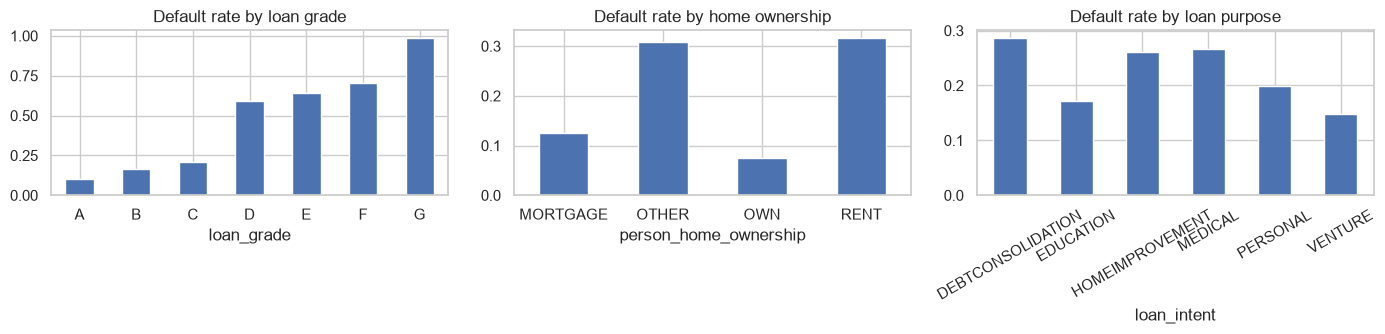

In [5]:
print(df["loan_status"].value_counts(), "\ndefault rate: %.3f" % df["loan_status"].mean())
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
df.groupby("loan_grade")["loan_status"].mean().plot.bar(ax=ax[0], color="#4C72B0", rot=0, title="Default rate by loan grade")
df.groupby("person_home_ownership")["loan_status"].mean().plot.bar(ax=ax[1], color="#4C72B0", rot=0, title="Default rate by home ownership")
df.groupby("loan_intent")["loan_status"].mean().plot.bar(ax=ax[2], color="#4C72B0", rot=30, title="Default rate by loan purpose")
plt.tight_layout(); plt.show()

**Figure 1.** 21.8 % of loans defaulted – the classes are imbalanced (78 / 22), so accuracy alone is not a good measure. The loan grade given by the lender is a very strong signal: grade A defaults in 10 % of cases, grade D in 59 %, grade G in 98 %. People who rent (32 %) default much more often than people who own a house (7 %). Loans for debt consolidation and medical needs are the riskiest (27–29 %), loans for a venture the safest (15 %).

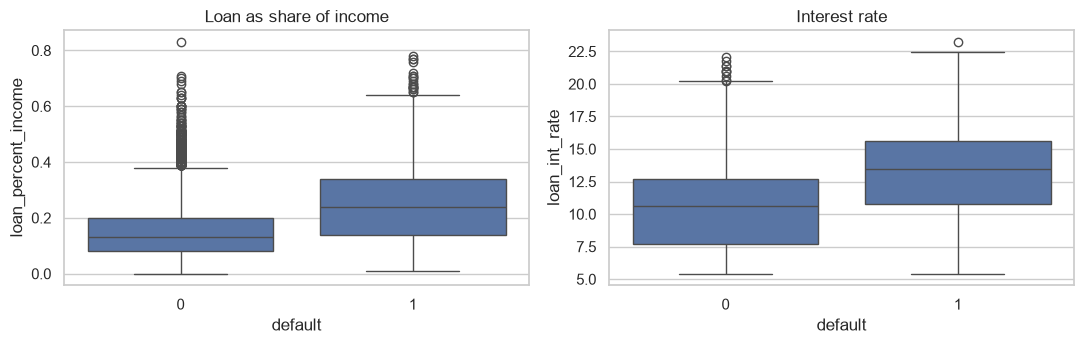

loan_percent_income
(0.0, 0.1]    0.12
(0.1, 0.2]    0.15
(0.2, 0.3]    0.22
(0.3, 0.4]    0.69
(0.4, 1.0]    0.74
Name: loan_status, dtype: float64


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.boxplot(data=df, x="loan_status", y="loan_percent_income", color="#4C72B0", ax=ax[0]).set(title="Loan as share of income", xlabel="default")
sns.boxplot(data=df, x="loan_status", y="loan_int_rate", color="#4C72B0", ax=ax[1]).set(title="Interest rate", xlabel="default")
plt.tight_layout(); plt.show()
print(df.groupby(pd.cut(df["loan_percent_income"], [0, 0.1, 0.2, 0.3, 0.4, 1]))["loan_status"].mean().round(2))

**Figure 2.** Defaulters take loans that are a bigger part of their income (median 0.24 vs 0.13) and pay a higher interest rate (median 13.5 % vs 10.6 %). The default rate jumps from 22 % to 69 % when the loan is more than 30 % of the yearly income – a natural "danger line" that will be used as a new feature.

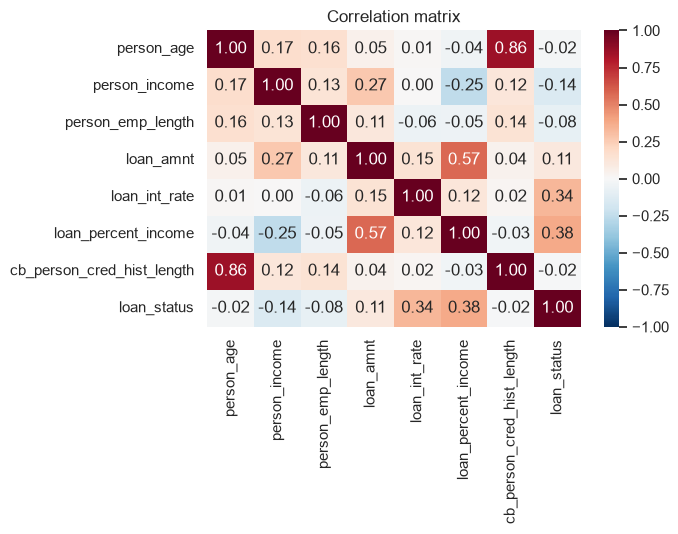

In [7]:
num = ["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length", "loan_status"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

**Figure 3.** The strongest linear correlations with default are the loan share of income (+0.38) and the interest rate (+0.34); income is negative (−0.14). Age and credit history length are almost perfectly correlated with each other (0.86) – both grow with time – but neither is related to default. The relations are weak in the linear sense, which is a hint that a non-linear model (kernel SVM) can do better than a linear one.

## 4. Data Cleaning

In [8]:
print("missing:", df.isna().sum()[df.isna().sum() > 0].to_dict())
print("duplicate rows:", df.duplicated().sum())
print("age > 90:", (df["person_age"] > 90).sum(), "| employment > 60 years:", (df["person_emp_length"] > 60).sum())
print("interest rate median by grade:", df.groupby("loan_grade")["loan_int_rate"].median().round(2).to_dict())

missing: {'person_emp_length': 895, 'loan_int_rate': 3116}
duplicate rows: 165
age > 90: 6 | employment > 60 years: 2
interest rate median by grade: {'A': 7.49, 'B': 10.99, 'C': 13.48, 'D': 15.31, 'E': 16.82, 'F': 18.54, 'G': 20.16}


In [9]:
before = len(df)
df = df.drop_duplicates()
df = df[(df["person_age"] <= 90) & ((df["person_emp_length"] <= 60) | df["person_emp_length"].isna())]
df["person_emp_length"] = df["person_emp_length"].fillna(df["person_emp_length"].median())
df["loan_int_rate"] = df["loan_int_rate"].fillna(df.groupby("loan_grade")["loan_int_rate"].transform("median"))
print("rows before:", before, "-> after:", len(df), "| missing values now:", df.isna().sum().sum())
print("max age:", df["person_age"].max(), "| max employment length:", df["person_emp_length"].max())

rows before: 32581 -> after: 32408 | missing values now: 0
max age: 84 | max employment length: 41.0


**What was done (before → after: 32 581 → 32 408 rows).**

* **Duplicates:** 165 identical rows removed.
* **Invalid values:** 6 borrowers older than 90 (123–144 years) and 2 with more than 60 years of employment removed – impossible values, most likely typos.
* **Missing values:** employment length (895) filled with the median (4 years). Interest rate (3 116) filled with the **median of the same loan grade** – the rate depends strongly on the grade (A ≈ 7.5 %, G ≈ 20 %), so this is much more accurate than one global median.
* **Data types:** correct – numbers are numeric, categories are text; no changes needed.
* **Outliers:** very high incomes (up to 2 million) are kept – they are real and the scaler handles them; the loan amount is limited to 35 000 by the lender, no outliers there.

## 5. Feature Engineering

**Created features**

| Feature | Formula | Potential impact |
|---|---|---|
| `interest_burden` | loan_amnt × loan_int_rate / income | yearly interest as a share of income – combines three columns into one "how heavy is this loan" number; a strong single predictor |
| `high_burden` | 1 if loan_percent_income > 0.3 | the "danger line" from Figure 2: above it the default rate is 70 % vs 15 % below; a simple rule that even a linear model can use |

**Kept:** all original features. `loan_grade` is kept as a category (A–G) and one-hot encoded – it is the lender's own risk score and the strongest single signal. `person_age` and `cb_person_cred_hist_length` are highly correlated, but SVM handles this without problems, so both stay.

**Removed:** nothing – the dataset is small (11 features) and every column has a business meaning.

In [10]:
df["interest_burden"] = df["loan_amnt"] * df["loan_int_rate"] / 100 / df["person_income"]
df["high_burden"] = (df["loan_percent_income"] > 0.3).astype(int)
print(df[["interest_burden", "high_burden", "loan_percent_income", "loan_int_rate", "loan_status"]].corr()["loan_status"].round(2))
print("share of high-burden loans: %.3f" % df["high_burden"].mean())

interest_burden        0.46
high_burden            0.43
loan_percent_income    0.38
loan_int_rate          0.33
loan_status            1.00
Name: loan_status, dtype: float64
share of high-burden loans: 0.118


`interest_burden` has the strongest correlation with default of all numeric features (0.46, vs 0.38 for the original loan share of income), and `high_burden` is close (0.43). Both created features should help the models.

## 6. Data Preprocessing

* X = 13 features, y = `loan_status`. Split 80 / 20 with `stratify=y` and `random_state=42`.
* Categories (`person_home_ownership`, `loan_intent`, `loan_grade`, `cb_person_default_on_file`) → OneHotEncoder. Numeric features → StandardScaler. **Scaling is critical for SVM**: the model works with distances between points, so without scaling the income (tens of thousands) would decide everything and the interest rate (5–23) would be ignored.
* Encoder and scaler are inside a `Pipeline`, so they learn only from the training set – no data leakage.
* SVM training time grows roughly with the square of the number of rows. The hyperparameter experiments (Section 7) are therefore run on a **stratified sample of 8 000 training loans** (a few seconds per model), and the final models are trained on the **full training set** (25 926 loans).

In [11]:
X = df.drop(columns=["loan_status"])
y = df["loan_status"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
cat_cols = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]
num_cols = [c for c in X.columns if c not in cat_cols]
prep = ColumnTransformer([("num", StandardScaler(), num_cols), ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
X_small, _, y_small, _ = train_test_split(X_train, y_train, train_size=8000, random_state=42, stratify=y_train)
print(X_train.shape, X_test.shape, X_small.shape, "| default share train: %.3f test: %.3f" % (y_train.mean(), y_test.mean()))

(25926, 13) (6482, 13) (8000, 13) | default share train: 0.219 test: 0.219


## 7. SVM Concepts and Training

**Large-margin classification** (Cortes & Vapnik, 1995; Géron, 2019, ch. 5). An SVM looks for the line (in 2D), plane (in 3D) or hyperplane (in many dimensions) that separates the two classes. Many lines can separate the data; SVM chooses the one that is as far as possible from the nearest points of both classes. The distance from the line to these nearest points is the **margin**, and the nearest points themselves are the **support vectors** – only they define the border; all other points could be removed and the border would not change. A wide margin means the model is less sensitive to noise and generalises better.

**Soft margin and C** (Géron, 2019, ch. 5). Real data cannot be separated perfectly. The parameter **C** says how much the model is punished for points that are on the wrong side or inside the margin. Small C = wide margin, many violations allowed, simpler model (risk of under-fitting). Large C = narrow margin, few violations, the model follows the training points closely (risk of over-fitting).

**Kernels** (James et al., 2021, ch. 9; Géron, 2019, ch. 5). A linear SVM can only draw a straight border. The **kernel trick** computes the similarity of two loans as if their features were mapped into a higher-dimensional space, where a straight border is possible – in the original space it looks curved. The *polynomial* kernel builds borders from polynomial combinations of features (parameter **degree**); the *RBF (Gaussian) kernel* builds smooth curved borders around groups of points (parameter **gamma** = how far the influence of one point reaches: small gamma = smooth wide border, large gamma = the border wraps around individual points and over-fits).

**SVM for regression (SVR)** (Géron, 2019, ch. 5). Our task is classification, but the same idea works for regression: SVR fits a "tube" of width **epsilon** around the data and punishes only the points outside the tube, instead of maximising the margin between classes.

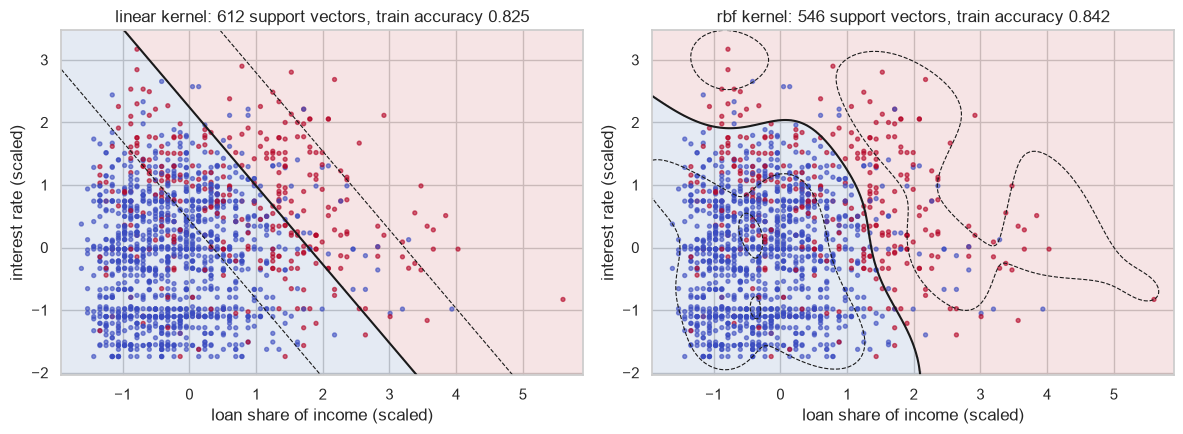

In [12]:
demo_X, _, demo_y, _ = train_test_split(X_train, y_train, train_size=1500, random_state=42, stratify=y_train)
Z = StandardScaler().fit_transform(demo_X[["loan_percent_income", "loan_int_rate"]])
xx, yy = np.meshgrid(np.linspace(Z[:, 0].min() - 0.3, Z[:, 0].max() + 0.3, 200), np.linspace(Z[:, 1].min() - 0.3, Z[:, 1].max() + 0.3, 200))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, kernel in zip(ax, ["linear", "rbf"]):
    m = SVC(kernel=kernel, C=1, gamma="scale").fit(Z, demo_y)
    zz = m.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    a.contourf(xx, yy, zz > 0, alpha=0.15, colors=["#4C72B0", "#C44E52"])
    a.contour(xx, yy, zz, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[0.8, 1.5, 0.8])
    a.scatter(Z[:, 0], Z[:, 1], c=demo_y, cmap="coolwarm", s=8, alpha=0.6)
    a.set(title=f"{kernel} kernel: {m.n_support_.sum()} support vectors, train accuracy {m.score(Z, demo_y):.3f}", xlabel="loan share of income (scaled)", ylabel="interest rate (scaled)")
plt.tight_layout(); plt.show()

**Figure 4** (1 500 loans, only two features, red = default). The solid line is the decision border, the dashed lines are the margin. The linear kernel draws one straight line: "the bigger the loan share and the interest rate, the more risky". The RBF kernel draws a curved border that closes around the risky region in the top-right corner and follows the data better (train accuracy 0.842 vs 0.825 on these two features). Both models use only about 550–600 of 1 500 points as support vectors.

### 7.1 Experiments with kernels and hyperparameters

All experiments use the 8 000-loan training sample and are scored on the test set. A helper trains a model with the full preprocessing pipeline and returns the four metrics.

In [13]:
def fit_score(model, Xtr, ytr, name):
    pipe = Pipeline([("prep", prep), ("model", model)]).fit(Xtr, ytr)
    p = pipe.predict(X_test)
    return pipe, {"model": name, "Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p), "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p)}

exp = []
for C in [0.1, 1, 10, 100]:
    exp.append(fit_score(SVC(kernel="rbf", C=C, gamma="scale"), X_small, y_small, f"RBF, C={C}, gamma=scale")[1])
pd.DataFrame(exp).round(3)

,model,Accuracy,Precision,Recall,F1
0,"RBF, C=0.1, gamma=scale",0.888,0.903,0.546,0.680
1,"RBF, C=1, gamma=scale",0.910,0.935,0.635,0.756
2,"RBF, C=10, gamma=scale",0.919,0.936,0.676,0.785
3,"RBF, C=100, gamma=scale",0.907,0.841,0.710,0.770


**Effect of C (RBF kernel).** F1 grows from 0.680 (C = 0.1) to 0.756 (C = 1) and 0.785 (C = 10), then falls to 0.770 at C = 100. A small C gives a too wide margin – the model is too simple and misses many defaulters (recall 0.55). A very large C gives a narrow margin that fits the training sample too closely – recall grows a little (0.71) but precision and accuracy fall. **C = 10** is the best compromise.

In [14]:
exp = []
for g in [0.005, 0.02, "scale", 0.2, 1]:
    exp.append(fit_score(SVC(kernel="rbf", C=10, gamma=g), X_small, y_small, f"RBF, C=10, gamma={g}")[1])
pd.DataFrame(exp).round(3)

,model,Accuracy,Precision,Recall,F1
0,"RBF, C=10, gamma=0.005",0.892,0.811,0.658,0.726
1,"RBF, C=10, gamma=0.02",0.912,0.927,0.648,0.763
2,"RBF, C=10, gamma=scale",0.919,0.936,0.676,0.785
3,"RBF, C=10, gamma=0.2",0.905,0.853,0.685,0.759
4,"RBF, C=10, gamma=1",0.845,0.738,0.451,0.560


**Effect of gamma (RBF kernel, C = 10).** With a very small gamma (0.005) the border is almost linear – F1 0.726, close to the linear SVM. `gamma="scale"` (≈ 1 / number of features ≈ 0.04 here) gives the best F1 0.785. When gamma grows to 0.2 and 1 the border starts to wrap around single training points: F1 falls to 0.759 and then to 0.560 – classic over-fitting. So gamma controls the "smoothness" of the border and is as important as C.

In [15]:
exp = []
exp.append(fit_score(SVC(kernel="linear", C=1), X_small, y_small, "Linear, C=1")[1])
for d in [2, 3]:
    exp.append(fit_score(SVC(kernel="poly", degree=d, C=10, gamma="scale", coef0=1), X_small, y_small, f"Polynomial, degree={d}, C=10")[1])
exp.append(fit_score(SVC(kernel="rbf", C=10, gamma="scale"), X_small, y_small, "RBF, C=10, gamma=scale")[1])
pd.DataFrame(exp).round(3)

,model,Accuracy,Precision,Recall,F1
0,"Linear, C=1",0.881,0.825,0.580,0.682
1,"Polynomial, degree=2, C=10",0.911,0.925,0.645,0.760
2,"Polynomial, degree=3, C=10",0.918,0.921,0.686,0.786
3,"RBF, C=10, gamma=scale",0.919,0.936,0.676,0.785


**Effect of the kernel and degree.** The linear kernel gives F1 0.682. The polynomial kernel of degree 2 improves it to 0.760 and degree 3 to 0.786 – a higher degree allows a more flexible border (interactions between three features, for example loan share × grade × home ownership). The RBF kernel reaches practically the same F1 (0.785). So the border between good and bad borrowers is clearly **non-linear**, and both non-linear kernels find it; RBF is a little faster to train and has one parameter less.

### 7.2 Final models on the full training set

Three models are trained on all 25 926 training loans with the best settings from the experiments: a **linear SVM** (`LinearSVC`, C = 1), a **polynomial SVM** (degree 3, C = 10) and an **RBF SVM** (C = 10, gamma = scale).

In [16]:
results, fitted = [], {}
for name, model in [("Linear SVM (C=1)", LinearSVC(C=1, max_iter=10000)),
                    ("Polynomial SVM (degree=3, C=10)", SVC(kernel="poly", degree=3, C=10, gamma="scale", coef0=1)),
                    ("RBF SVM (C=10, gamma=scale)", SVC(kernel="rbf", C=10, gamma="scale"))]:
    pipe, r = fit_score(model, X_train, y_train, name)
    r["train accuracy"] = accuracy_score(y_train, pipe.predict(X_train))
    results.append(r); fitted[name] = pipe
    print(name, "done")

Linear SVM (C=1) done


Polynomial SVM (degree=3, C=10) done


RBF SVM (C=10, gamma=scale) done


## 8. Evaluation

In [17]:
res = pd.DataFrame(results).set_index("model").round(3)
res["meets criteria"] = (res["Recall"] >= 0.65) & (res["Precision"] >= 0.80) & (res["F1"] >= 0.75)
res

,Accuracy,Precision,Recall,F1,train accuracy,meets criteria
model,,,,,,
Linear SVM (C=1),0.876,0.761,0.633,0.691,0.878,False
"Polynomial SVM (degree=3, C=10)",0.924,0.948,0.690,0.799,0.928,True
"RBF SVM (C=10, gamma=scale)",0.925,0.950,0.694,0.802,0.932,True


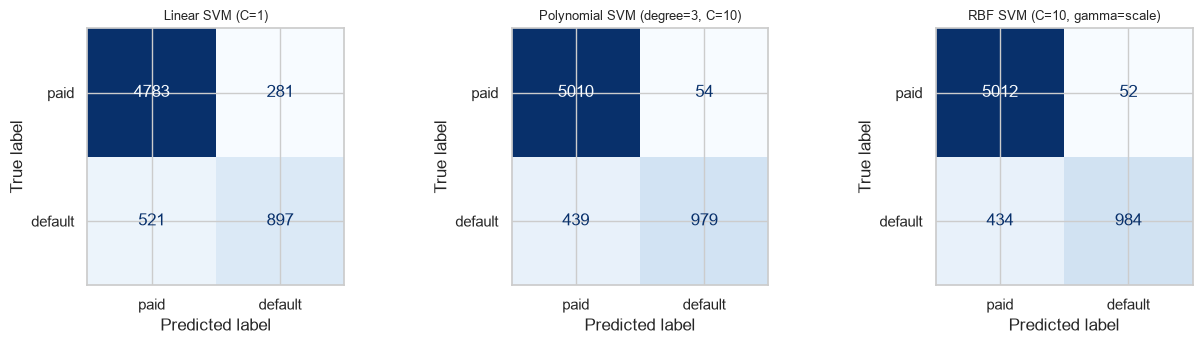

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, (name, pipe) in zip(ax, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, display_labels=["paid", "default"], cmap="Blues", ax=a, colorbar=False)
    a.set_title(name, fontsize=9)
plt.tight_layout(); plt.show()

**Confusion matrices (test set, 6 482 loans, 1 418 defaults).** Linear SVM: 897 defaulters found, 521 missed, 281 false alarms. Polynomial SVM: 979 found, 439 missed, 54 false alarms. **RBF SVM: 984 found, 434 missed, only 52 false alarms.**

**Comparison table.** The linear SVM has accuracy 0.876, precision 0.761, recall 0.633, F1 0.691. The two non-linear kernels are far ahead and almost equal: polynomial – accuracy 0.924, precision 0.948, recall 0.690, F1 0.799; **RBF – accuracy 0.925, precision 0.950, recall 0.694, F1 0.802**. Train accuracy is close to test accuracy for all three (0.878 / 0.928 / 0.932), so there is no over-fitting.

**Best model: RBF SVM with C = 10 and gamma = scale.** It has the highest value of every metric. The reason is the shape of the data: the risk of default depends on *combinations* of factors (loan share of income × grade × home ownership), which a straight border cannot express and a curved kernel border can. The kernel adds +0.11 F1 and cuts the number of good clients wrongly rejected from 281 to 52.

**Most important metric.** Recall of the default class – every missed defaulter is lost money. The RBF SVM catches 69 % of them, and with precision 0.95 almost every rejected client was really risky. The remaining 31 % of missed defaulters are borrowers who look good on paper (good grade, low loan share) – no model can see them from the application form only.

**Business criteria.** The RBF SVM meets all four thresholds (recall 0.694 ≥ 0.65, precision 0.950 ≥ 0.80, F1 0.802 ≥ 0.75, accuracy 0.925 > 0.78); the polynomial SVM meets them too. The linear SVM fails on recall (0.63) and precision (0.76).

## 9. Conclusion

* **Data:** 32 581 loans (Kaggle), 22 % defaults. Cleaning: 165 duplicates and 8 impossible ages / employment lengths removed, employment length filled with the median, interest rate filled with the median of the same loan grade → 32 408 loans.
* **Features:** two created – `interest_burden` (yearly interest as a share of income, the strongest numeric predictor) and `high_burden` (loan above 30 % of income). Categories one-hot encoded, numbers scaled inside a pipeline – scaling is a must for SVM.
* **Models and kernels:** linear SVM, polynomial SVM (degree 2 and 3) and RBF SVM; hyperparameters C (0.1–100), gamma (0.005–1) and degree (2–3) were tested on an 8 000-loan sample.
* **Results (test):** Linear SVM F1 0.691; Polynomial SVM (degree 3, C = 10) F1 0.799; **RBF SVM (C = 10, gamma = scale) F1 0.802, accuracy 0.925, precision 0.950, recall 0.694** – the best configuration. It wins because the border between good and bad borrowers is curved; C = 10 balances margin width and training errors, and the default gamma keeps the border smooth. Too small C or gamma under-fits (F1 0.68–0.73), too large gamma over-fits badly (F1 0.56).
* **Business criteria:** met by the RBF and polynomial SVMs, not by the linear SVM.
* **Improvements:** (1) recall of 0.69 means 3 of 10 defaulters are still approved – `class_weight="balanced"` or a lower decision threshold would raise recall at the price of precision, and the bank should choose the point that matches its costs; (2) a full grid search of C and gamma together on the whole training set (here the search was done on a sample to save time); (3) SVM is slow on large data – for a real bank with millions of loans, gradient boosting would be a more practical choice, and the model should be re-trained regularly on fresh loans.

## 10. References

Géron, A. (2019). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow: Concepts, tools, and techniques to build intelligent systems* (2nd ed.). O'Reilly Media. (Chapter 5: support vector machines)

Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273–297. https://doi.org/10.1007/BF00994018

James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An introduction to statistical learning with applications in R* (2nd ed.). Springer. (Chapter 9: support vector machines)

Lao Tse. (2020). *Credit risk dataset* [Data set]. Kaggle. https://www.kaggle.com/datasets/laotse/credit-risk-dataset

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.